# **Practice 4.2: Neural Networks (Classification)**

<hr>

## **1. Introduction**
In the previous practice, we learned how to solve regression problems using neural networks. In this session, we will explore how to solve **classification problems**.

Until now, we have focused on binary classification problems, but in this practice, we will also address two new types.

### **Objectives**
In this practice, you will learn to:
* Distinguish between different types of classification problems.
* Modify a neural network to learn classification problems.
* Transform categorical variables into numerical ones.

Let's begin by loading our data once again:

In [ ]:
import pandas as pd

seed = 2533
data = pd.read_pickle('https://raw.githubusercontent.com/AIC-Uniovi/Sistemas-Inteligentes/refs/heads/main/datasets/f1_23_monaco.pkl')

<hr>

## **2. Binary Classification Problems**

Let's try to solve a problem similar to the one in Practice 3 on classification, that is:

<div class="alert alert-block alert-success">
    <b>Create a model that, given the time (in seconds) of the first two sectors of an <i>Aston Martin</i> driver (<code>'Sector1Time', 'Sector2Time'</code>), predicts whether that time was set by <i>Alonso</i> or not (<i>Stroll</i>).</b>
</div>

As always, the first step is to create the necessary datasets to train a model.

### **2.1. Data Preprocessing**

We create the variable <code>data_aston</code> with the rows and columns needed to train our models.

In [ ]:
data_aston = data.loc[data.Team == 'Aston Martin'][['Sector1Time', 'Sector2Time', 'Driver']].copy()
data_aston['Sector1Time'] = data_aston['Sector1Time'].dt.total_seconds()
data_aston['Sector2Time'] = data_aston['Sector2Time'].dt.total_seconds()



<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create the <code>Class</code> column in the <code>data_aston</code> DataFrame so that it is zero whenever the driver is not Alonso, and 1 otherwise.
</div>

In [ ]:
# Your code here


data_aston['Class'] = data_aston['Driver'].apply(lambda x: 1 if x == 'ALO' else 0)



<div class="alert alert-block alert-info">
    <b>Exercise:</b> Separate the X and Y from the <code>data_aston</code> DataFrame, split them into training and test sets (80/20) setting the random seed, and finally <b>standardize</b> the X variables.
</div>

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Your code here



X = data_aston[['Sector1Time', 'Sector2Time']]
Y = data_aston['Class']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=seed)

scaler = StandardScaler()
X_train_sd = scaler.fit_transform(X_train)
X_test_sd = scaler.transform(X_test)




### **2.2. Machine Learning**

With the data ready, we will once again train and evaluate the machine learning models we already know, so we can compare them with our new system.

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Train and evaluate the remaining models (<i>Logistic Regression</i>, <i>K-Nearest Neighbors</i>, <i>Decision Trees</i>, and <i>SVC</i>) using the following function.
</div>

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from tabulate import tabulate
from sklearn.dummy import DummyClassifier


from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyRegressor  

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC


def evaluate_model(Y_test, preds_test, model_name, average = 'binary'):
    preds_test = (preds_test >= 0.5).astype(int)
    metrics = [
        ('Accuracy', accuracy_score(Y_test, preds_test)),
        ('F1', f1_score(Y_test,preds_test, average=average))
    ]
    
    print(f'Results for {model_name}:')
    print(tabulate(metrics, headers = ['Metric', 'TEST'], tablefmt = 'rounded_outline'))
    print()

# Baseline Random
baseline_random = DummyClassifier(strategy = 'uniform', random_state=seed)
baseline_random.fit(X_train_sd, Y_train)
preds_test = baseline_random.predict(X_test_sd)
evaluate_model(Y_test, preds_test, 'Baseline Random')

# Baseline Zero-R
baseline_zero = DummyClassifier(strategy = 'most_frequent', random_state=seed)
baseline_zero.fit(X_train_sd, Y_train)
preds_test = baseline_zero.predict(X_test_sd)
evaluate_model(Y_test, preds_test, 'Baseline Zero-R')


#Logistic Classifier

model_lr = LogisticRegression(random_state=seed)
model_lr.fit(X_train_sd, Y_train)
preds_test = model_lr.predict(X_test_sd)
evaluate_model(Y_test, preds_test, 'Logistic Regression')


# KNN
model_knn = KNeighborsClassifier()
model_knn.fit(X_train_sd, Y_train)
preds_test = model_knn.predict(X_test_sd)
evaluate_model(Y_test, preds_test, 'K-Nearest Neighbors')



# Decision Trees
model_tree = DecisionTreeClassifier()
model_tree.fit(X_train_sd, Y_train)
preds_test = model_tree.predict(X_test_sd)
evaluate_model(Y_test, preds_test, 'Decision Trees')

# SVC
model_svc = SVC()
model_svc.fit(X_train_sd, Y_train)
preds_test = model_svc.predict(X_test_sd)
evaluate_model(Y_test, preds_test, 'SVC')

The results should look something like this:

<center>

| Model                 | Accuracy (test) | F1 (test) |
|-----------------------|-----------------|-----------|
| Baseline Random       | 0.522           | 0.560     |
| Baseline Zero-R       | 0.565           | 0.722     |
| Logistic Regression   | 0.565           | 0.722     |
| KNN                   | 0.957           | 0.963     |
| Decision Trees        | 0.826           | 0.867     |
| SVC                   | 0.913           | 0.929     |

</center>

##### **Visualizing Data and Models**

In this case, our problem has two inputs and one output (the class). As we saw in the regression part, working with such low dimensions allows us to visualize the behavior of the data and the models we are learning.

Thanks to this possibility, we can analyze in advance whether the relationship between the inputs and outputs can be solved with linear models or, on the other hand, requires a non-linear approach.

Below is the function that visualizes the data and, given a model, makes a series of predictions to draw its **decision boundary**:

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Function to visualize data and model decision boundary
def plot_decision_boundary(X_train, Y_train, X_test, Y_test, model, model_name):
    plt.figure(figsize = (8, 6))

    # Create a mesh grid of points within the range of Train and Test data
    x_min, x_max = min(X_train[:, 0].min(), X_test[:, 0].min()) - 0.5, max(X_train[:, 0].max(), X_test[:, 0].max()) + 0.5
    y_min, y_max = min(X_train[:, 1].min(), X_test[:, 1].min()) - 0.5, max(X_train[:, 1].max(), X_test[:, 1].max()) + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # Predict the probability for each point in the mesh
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    # Draw the decision boundary
    contour = plt.contourf(xx, yy, Z, levels = [0, 0.5, 1], alpha = 0.7, cmap = 'coolwarm')

    # Add colorbar
    plt.colorbar(contour)

    # Visualize the Train points
    plt.scatter(X_train[:, 0], X_train[:, 1], c = Y_train, cmap = 'coolwarm', edgecolors = 'k', label = 'Train Data')
    
    # Visualize the Test points
    plt.scatter(X_test[:, 0], X_test[:, 1], c = Y_test, cmap = 'coolwarm', marker = 'X', label = 'Test Data')

    # Labels and legend
    plt.xlabel('Sector1Time')
    plt.ylabel('Sector1Time')
    plt.title(f'Decision Boundary: {model_name}')
    plt.legend()
    plt.show()

plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, baseline_random, 'Baseline Random')
plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, baseline_zero, 'Baseline Zero-R')


the resty

In [ ]:
# Your code here
plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, model_lr, 'Logistic Regressor')
plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, model_knn, 'KNN')
plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, model_tree, 'Decission tree')
plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, model_svc, 'SVC')

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Do you think the problem is linear or non-linear? Analyzing the decision boundaries, which models are non-linear?
</div>

Your answer here

### **2.3. Neural Network**

Now we will create a neural network from scratch to solve this problem. Remember that the steps are as follows:

1) Create the model architecture.
2) Specify the optimizer, loss function, and compile.
3) Train and evaluate.

We will set the seeds and create the function to plot the model's training evolution:

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
import pandas as pd
import numpy as np
import os, random

# Set the libraries' seeds so that the results are reproducible.
os.environ['PYTHONHASHSEED'] = str(seed)
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

def plot_loss_history(history):
    # Extract the data from the history
    loss = history.history['loss']
    val_loss = history.history.get('val_loss', None)  # It may not exist if validation wasn't used
    epochs = range(1, len(loss) + 1)

    # Create a DataFrame for seaborn
    data = pd.DataFrame({ 'Epoch': list(epochs) * 2, 'Loss': loss + (val_loss if val_loss else []), 'Type': ['Train'] * len(loss) + (['Validation'] * len(val_loss) if val_loss else []) })

    # Create the plot
    plt.figure(figsize = (10, 5))
    sns.lineplot(data = data, x = 'Epoch', y = 'Loss', hue = 'Type')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Evolution during Training')
    plt.legend(title = 'Dataset')
    plt.grid(True)
    plt.show()

##### **Activation in the Last Layer and Loss**

As mentioned in the previous practice, when creating a neural network, it is crucial to properly select both the **activation function of the last layer** and the **loss function**.

In a regression problem, the last layer generally does not use an activation function to avoid limiting the predictions to a specific range. However, if the values being predicted are always positive, a *ReLU* function could be applied.

<center>
    <div style="border-radius:5px; padding:10px; background:white; max-width:900px">
        <img src="https://i.imgur.com/e7kd5fs.png">   
    </div>
</center>

Now, we are facing a **binary classification** problem, where we seek to predict a probability, i.e., a value between $0$ and $1$. Therefore, we need to use a **sigmoid** activation function in the final layer.

<div class="alert alert-block alert-warning">
    <strong>Note:</strong> Remember that a neural network with a <b>single</b> activation function in the last layer <b>cannot learn non-linear problems</b>; activation functions are required in the hidden layers for that.
</div>

Another aspect we need to change compared to regression problems is the **loss function**.

<div class="alert alert-block alert-warning">
    <strong>Note:</strong> In a binary classification problem, loss functions designed for regression, such as <b>mean absolute error</b> (MAE), should not be used, as they are oriented to problems where the outputs are <b>continuous values, not probabilities</b>.
</div>

Therefore, in addition to adding a sigmoid to the output layer, we must also change the loss function to **Binary Crossentropy**. This leaves us with the following table:

<center>

| Problem Type                 | Activation Function in Last Layer           | Loss Function          | In *Keras*                                |
|------------------------------|--------------------------------------------|------------------------|-------------------------------------------|
| *Regression*                 | None or *ReLU* (if values are positive)   | *MAE* or *MSE*         | `mean_absolute_error` or `mean_squared_error` |
| *Binary Classification*      | *Sigmoid*

<center>

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create, within the provided function, a <b>binary classification</b> neural network with a single layer. Train it, plot the evolution of the loss using the <code>plot_loss_history</code> function, and analyze its decision boundary.
    <hr>
    Train with a validation set of 20%, for 300 epochs, with a batch size of 16 and a learning rate of 0.005.
</div>

In [ ]:
from tensorflow.keras.models import Sequential  
from tensorflow.keras.layers import Dense, Input  
from tensorflow.keras.optimizers import Adam


def neural_network_one(learning_rate):
    # Create and compile the model
    model = Sequential()
    model.add(Input(shape = (2,)))  
    model.add(Dense(1, activation='sigmoid', name = 'sigmoid_layer'))


    # Your code here
    optim = Adam(learning_rate = learning_rate)
    model.compile(loss = 'binary_crossentropy', optimizer = optim )

    return model

# Create the neural network from scratch
model_1 = neural_network_one(learning_rate = 0.005)

# Train the model
# Your code here
history_1 = model_1.fit(X_train_sd, Y_train, validation_split = 0.2, batch_size = 16, epochs = 300)


# Visualize training
# Your code here
plot_loss_history(history_1)





# Decision boundary
# Your code here
plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, model_1, 'Neural Network')

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Evaluate the previous model on Test using <code>.predict()</code> and <code>evaluate_model</code>. Add the result to the table.
    <hr>
    In this case, we are <b>not</b> going to try to find the best hyperparameters; as you have seen, this model is linear and will not be able to solve our non-linear problem.
</div>

<center>

| Model                  | Accuracy (test) | F1 (test) |
|------------------------|-----------------|-----------|
| Baseline Random        | 0.522           | 0.560     |
| Baseline Zero-R        | 0.565           | 0.722     |
| Logistic Regression    | 0.565           | 0.722     |
| KNN                    | 0.957           | 0.963     |
| Decision Trees         | 0.826           | 0.867     |
| SVC                    | 0.913           | 0.929     |
| Linear Neural Network  |                 |           |

</center>

In [ ]:
# Evaluate
# Your code here

preds_test = model_1.predict(X_test_sd)

evaluate_model(Y_test,preds_test, "NN")

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create, within the provided function, a <b>binary classification</b> neural network with a single layer. Train it and plot the evolution of the loss using the <code>plot_loss_history</code> function.
    <hr>
    Train with a validation set of 20%, for 200 epochs, with a batch size of 16 and a learning rate of 0.001.
</div>



<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create a <u>non-linear</u> binary classification neural network and search for the best learning rate. Train the final model with the best hyperparameter and evaluate it on test. Fill in both tables.
    <hr>
    Set the validation set to 20%, epochs to 500, and batch size to 16. For training the final model, a validation set is not necessary.
    <hr style="margin-bottom:5px">
    Also, visualize the decision boundary to verify that the learned model is non-linear.
</div>

<center>

| Model                       | Accuracy (train)  | F1 (train) | Accuracy (val)  | F1 (val) |
|-----------------------------|-------------------|------------|-----------------|----------|
| *Neural Network (lr=0.001)*  |                   |            |                 |          |
| *Neural Network (lr=0.005)*  |                   |            |                 |          |
| *Neural Network (lr=0.01)*   |                   |            |                 |          |

</center>

<br>

<center>

| Model                     | Accuracy (test) | F1 (test) |
|---------------------------|-----------------|-----------|
| Baseline Random           | 0.522           | 0.560     |
| Baseline Zero-R           | 0.565           | 0.722     |
| Logistic Regression       | 0.565           | 0.722     |
| KNN                       | 0.957           | 0.963     |
| Decision Trees            | 0.826           | 0.867     |
| SVC                       | 0.913           | 0.929     |
| Linear Neural Network     |                 |           |
| Non-Linear Neural Network |                 |           |

</center>

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4409 - val_loss: 0.4911
Epoch 355/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4403 - val_loss: 0.4906
Epoch 356/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4397 - val_loss: 0.4901
Epoch 357/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4391 - val_loss: 0.4896
Epoch 358/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4385 - val_loss: 0.4891
Epoch 359/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4379 - val_loss: 0.4886
Epoch 360/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4373 - val_loss: 0.4882
Epoch 361/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.4367 - val_loss: 0.4877
Epoch 362/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4362 - val_loss: 0.4872
Epoch 363/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4356 - val_loss: 0.4867
Epoch 364/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4350 - val_loss: 0.4863
Epoch 365/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4344 -

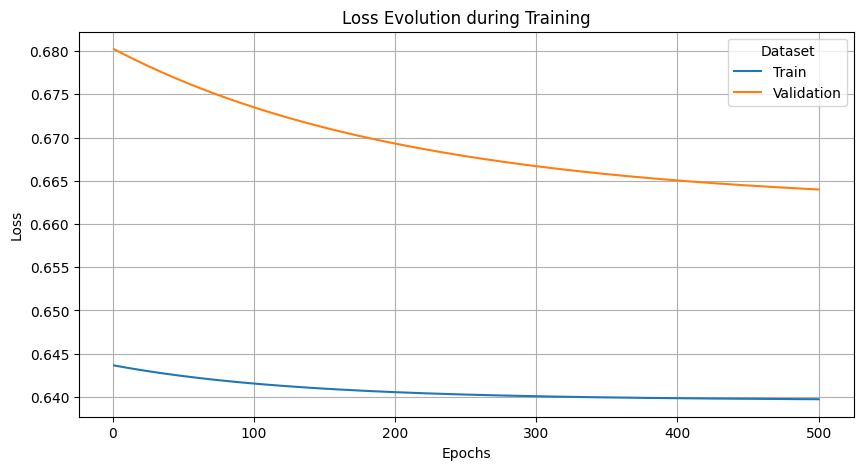

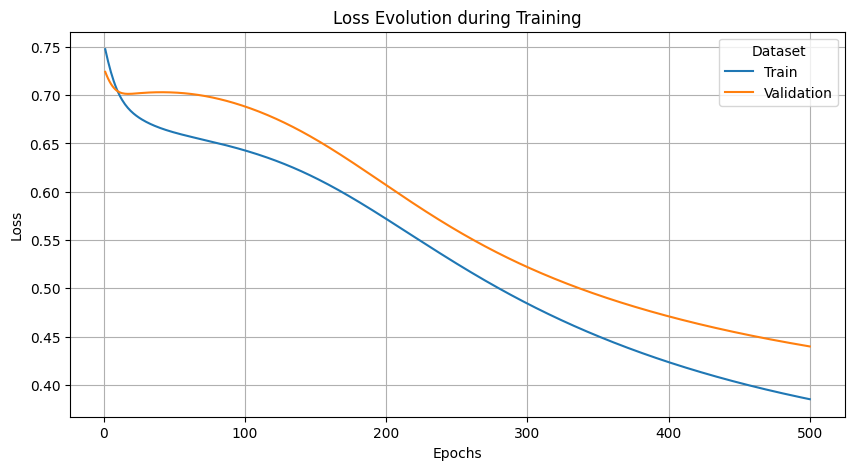

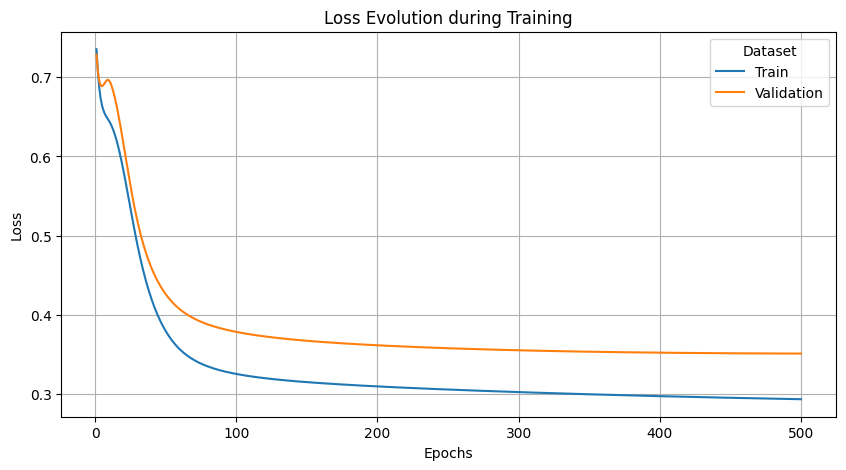

In [43]:
def neural_network_two(learning_rate):
    model = Sequential()
    model.add(Input(shape = (2,)))
    model.add(Dense(10, activation='tanh', name = 'hidden_layer'))
    model.add(Dense(1, activation='sigmoid', name = 'output_layer'))
    optim = Adam(learning_rate = learning_rate)
    model.compile(loss = 'binary_crossentropy', optimizer = optim)

    return model

# Create the neural network from scratch
model_2 = neural_network_two(learning_rate = 0.001)
model_3 = neural_network_two(learning_rate = 0.01)


# Train the model
# Your code here
history_1 = model_1.fit(X_train_sd, Y_train, validation_split = 0.2, batch_size = 16, epochs = 500)
history_2 = model_2.fit(X_train_sd, Y_train, validation_split = 0.2, batch_size = 16, epochs = 500)
history_3 = model_3.fit(X_train_sd, Y_train, validation_split = 0.2, batch_size = 16, epochs = 500)


# Visualize training
# Your code here
plot_loss_history(history_1)

plot_loss_history(history_2)
plot_loss_history(history_3)



# Repeat for another hyperparameter value

In [44]:
#loss: 0.6508 - val_loss: 0.6640        0.005
#loss: 0.3731 - val_loss: 0.4280        0.001
#loss: 0.3103 - val_loss: 0.3578        0.1


Epoch 1/500
6/6 - 0s - 46ms/step - loss: 0.6542
Epoch 2/500
6/6 - 0s - 5ms/step - loss: 0.5785
Epoch 3/500
6/6 - 0s - 4ms/step - loss: 0.4940
Epoch 4/500
6/6 - 0s - 5ms/step - loss: 0.4212
Epoch 5/500
6/6 - 0s - 4ms/step - loss: 0.4043
Epoch 6/500
6/6 - 0s - 4ms/step - loss: 0.3685
Epoch 7/500
6/6 - 0s - 4ms/step - loss: 0.3422
Epoch 8/500
6/6 - 0s - 5ms/step - loss: 0.3586
Epoch 9/500
6/6 - 0s - 5ms/step - loss: 0.3449
Epoch 10/500
6/6 - 0s - 4ms/step - loss: 0.3326
Epoch 11/500
6/6 - 0s - 4ms/step - loss: 0.3417
Epoch 12/500
6/6 - 0s - 5ms/step - loss: 0.3331
Epoch 13/500
6/6 - 0s - 4ms/step - loss: 0.3306
Epoch 14/500
6/6 - 0s - 5ms/step - loss: 0.3326
Epoch 15/500
6/6 - 0s - 4ms/step - loss: 0.3277
Epoch 16/500
6/6 - 0s - 4ms/step - loss: 0.3284
Epoch 17/500
6/6 - 0s - 5ms/step - loss: 0.3271
Epoch 18/500
6/6 - 0s - 4ms/step - loss: 0.3253
Epoch 19/500
6/6 - 0s - 4ms/step - loss: 0.3254
Epoch 20/500
6/6 - 0s - 5ms/step - loss: 0.3238
Epoch 21/500
6/6 - 0s - 4ms/step - loss: 0.3233


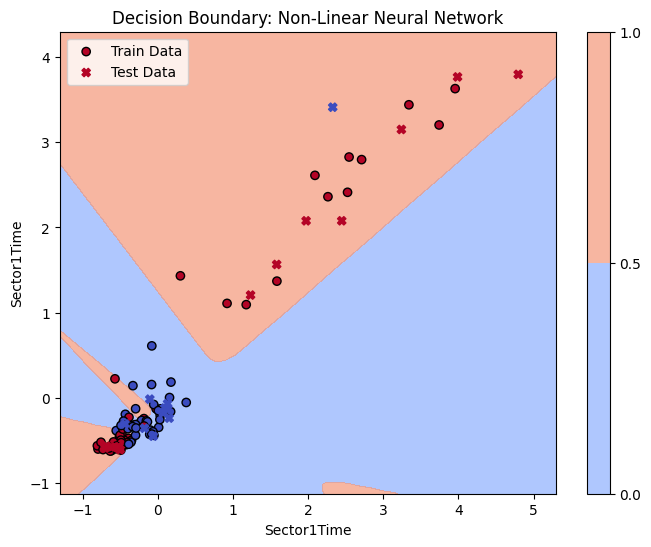

In [45]:
# Train final model (without validation)

best_lr = 0.1

final_model = neural_network_two(learning_rate = best_lr)
final_model.fit(X_train_sd, Y_train, batch_size = 16, epochs = 500, verbose = 2)

# Your code here

# Evaluate on test
# Your code here


test_preds = final_model.predict(X_test_sd)
evaluate_model(Y_test,test_preds, "Final Neural Network 0.1")


# Decision boundary
# Your code here


plot_decision_boundary(X_train_sd, Y_train, X_test_sd, Y_test, final_model, 'Non-Linear Neural Network')


<hr>

## **3. Multi-classification Problems**

So far, our classification problems have always focused on binary classification, but as you know, there are more types of problems in this area.

Now we will try to solve a **multi-class** problem, that is, a problem where each example can belong **to one of several possible classes**.

<div class="alert alert-block alert-success">
    <b>Create a model that, given the time (in seconds) of the sectors (<code>"Sector1Time", "Sector2Time" and "Sector3Time"</code>), the speeds (<code>"SpeedI1", "SpeedI2", "SpeedFL" and "SpeedST"</code>) and tire data (<code>"Compound" and "TyreLife"</code>), is able to predict the <i>team</i> (<code>"Team"</code>) of the car that made that lap.</b> 
</div>
  
As always, the first step will be to create the necessary datasets to train our model.

### **3.1. Data Preprocessing**

We create the <code>data_teams</code> variable with the rows and columns necessary to train our models.

In [46]:
relevant_cols = ['Sector1Time', 'Sector2Time', 'Sector3Time', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'Compound', 'TyreLife', 'Team']
data_teams = data[relevant_cols].copy()
data_teams = data_teams.dropna().reset_index(drop = True) # Remove rows with any null value

data_teams['Sector1Time'] = data_teams['Sector1Time'].dt.total_seconds()
data_teams['Sector2Time'] = data_teams['Sector2Time'].dt.total_seconds()
data_teams['Sector3Time'] = data_teams['Sector3Time'].dt.total_seconds()

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create a <code>countplot()</code> of the <code>"Team"</code> column from the DataFrame <code>data_teams</code> to check if there is any class imbalance. Do you think there is?
</div>

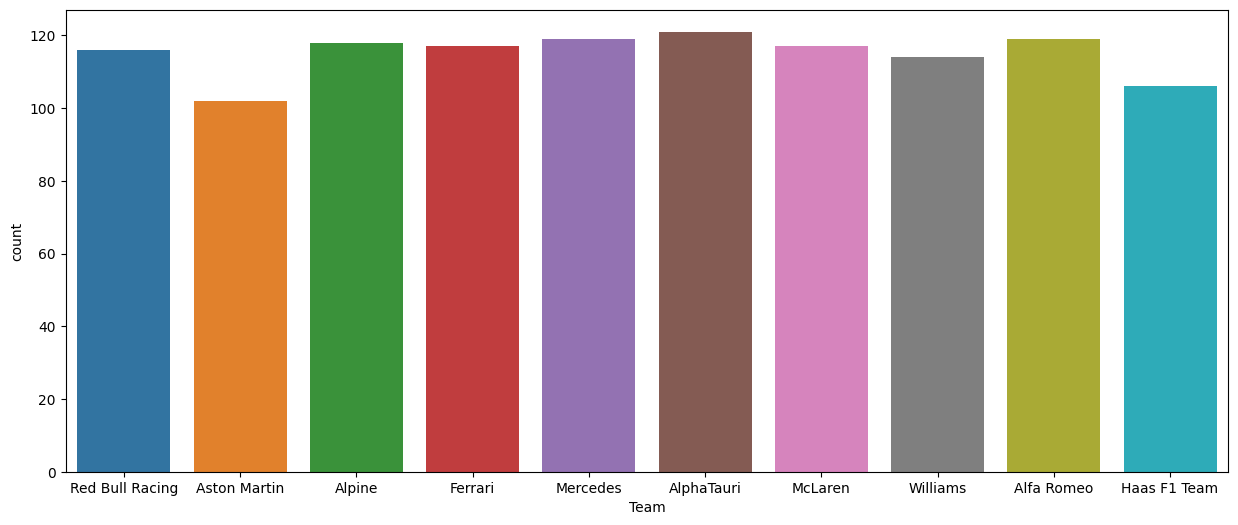

In [47]:
plt.figure(figsize = (15,6))

# Your code here
sns.countplot(data_teams, x='Team', hue='Team')
#Pq las clases están balanceadas, sino sería my complicado hacer un modelo

plt.show()

##### **Categorical to Numeric**

Next, we need to encode **numerically** all the columns that are of *text* or *categorical* type.

<div class="alert alert-block alert-warning">
    <strong>Note:</strong> Remember that a model cannot work with text, neither as input nor as output.
</div>

If the column we are trying to transform into a number only takes two values ('Yes' or 'No', 'Alonso' or 'Stroll', 'Sick' or 'Not Sick', ...), we can apply the same trick from previous exercises: assign a $1$ to one value and $0$ to the other.

The issue arises with columns where the model can take multiple values, such as the `Compound` feature in the input or the target variable `Team`. To encode these, a method known as **One-Hot** is used or, if each column can have more than one value, **Multi-Label Binarization**.

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Use the <code>pd.get_dummies()</code> method from <code>pandas</code> passing <code>data_teams</code> as a parameter. What happens?
    <hr>
    Once you understand it, overwrite <code>data_teams</code>.
</div>

In [48]:
# Your code here

data_teams_encoded = pd.get_dummies(data_teams, dtype=int)

data_teams_encoded




,Sector1Time,Sector2Time,Sector3Time,SpeedI1,SpeedI2,SpeedFL,SpeedST,TyreLife,Compound_HARD,Compound_INTERMEDIATE,...,Team_Alfa Romeo,Team_AlphaTauri,Team_Alpine,Team_Aston Martin,Team_Ferrari,Team_Haas F1 Team,Team_McLaren,Team_Mercedes,Team_Red Bull Racing,Team_Williams
0,20.954,37.366,21.047,186.0,182.0,256.0,259.0,2,0,0,...,0,0,0,0,0,0,0,0,1,0
1,20.871,37.656,21.119,194.0,181.0,255.0,272.0,3,1,0,...,0,0,0,1,0,0,0,0,0,0
2,21.245,37.737,21.319,172.0,178.0,256.0,275.0,2,0,0,...,0,0,1,0,0,0,0,0,0,0
3,21.218,37.827,21.548,190.0,177.0,257.0,278.0,2,1,0,...,0,0,0,0,1,0,0,0,0,0
4,21.226,37.769,21.532,178.0,183.0,257.0,274.0,2,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1144,22.610,41.552,22.416,170.0,172.0,257.0,279.0,24,0,1,...,0,0,1,0,0,0,0,0,0,0
1145,22.537,41.195,22.551,177.0,172.0,256.0,280.0,23,0,1,...,0,0,0,0,1,0,0,0,0,0
1146,22.670,41.227,22.718,174.0,171.0,257.0,277.0,25,0,1,...,1,0,0,0,0,0,0,0,0,0
1147,24.523,41.980,22.573,130.0,172.0,260.0,280.0,24,0,1,...,0,0,0,0,0,0,0,0,0,1


<div class="alert alert-block alert-info">
    <b>Exercise:</b> Separate the X and Y from the <code>data_teams</code> dataframe, split into training and test (80/20) by setting the seed, and finally <b>normalize</b> the X using the <code>MinMaxScaler()</code> class.
</div>

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

x_cols = ['Sector1Time', 'Sector2Time', 'Sector3Time', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'TyreLife', 'Compound_HARD', 'Compound_INTERMEDIATE', 'Compound_MEDIUM', 'Compound_SOFT', 'Compound_WET']
y_cols = ['Team_Alfa Romeo', 'Team_AlphaTauri', 'Team_Alpine', 'Team_Aston Martin', 'Team_Ferrari', 'Team_Haas F1 Team', 'Team_McLaren', 'Team_Mercedes', 'Team_Red Bull Racing', 'Team_Williams']


X = data_teams_encoded[x_cols]
Y = data_teams_encoded[y_cols]



X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=seed)


scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



# Your code here

### **3.2. Machine Learning**

With the data ready, we will train and evaluate the machine learning models we already know to compare them with our new system.

<div class="alert alert-block alert-warning">
    <strong>Note:</strong> The <code>f1_score</code> metric can be obtained in different ways for multi-class problems:
    <ul>
        <li><strong>micro</strong>: Calculates the global metric considering all samples, without distinguishing between classes. It's useful when the classes are imbalanced.</li>
        <li><strong>macro</strong>: Calculates the metric for each class separately and then takes the arithmetic average. It gives equal weight to all classes, regardless of their frequency.</li>
        <li><strong>weighted</strong>: Similar to macro, but weights each class according to its number of samples. It's useful when the classes are imbalanced.</li>
        <li><strong>samples</strong>: Used in multi-label problems, calculating the metric for each sample and then averaging it.</li>
    </ul>
</div>

As you saw in the previous histogram, the classes are balanced, so we can use `macro`.

In [50]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

# Baseline Random
baseline_random = DummyClassifier(strategy = 'uniform')
baseline_random.fit(X_train_scaled, Y_train)
preds_test = baseline_random.predict(X_test_scaled)
evaluate_model(Y_test, preds_test, 'Baseline Random', average = 'macro')

# Baseline Zero-R
baseline_zero = DummyClassifier(strategy = 'most_frequent')
baseline_zero.fit(X_train_scaled, Y_train)
preds_test = baseline_zero.predict(X_test_scaled)
evaluate_model(Y_test, preds_test, 'Baseline Zero-R', average = 'macro')

# KNN
model_knn = KNeighborsClassifier()
model_knn.fit(X_train_scaled, Y_train)
preds_test = model_knn.predict(X_test_scaled)
evaluate_model(Y_test, preds_test, 'KNN', average = 'macro')

# Decision Trees
model_tree = DecisionTreeClassifier()
model_tree.fit(X_train_scaled, Y_train)
preds_test = model_tree.predict(X_test_scaled)
evaluate_model(Y_test, preds_test, 'Decision Tree', average = 'macro')

Results for Baseline Random:
╭──────────┬────────────╮
│ Metric   │       TEST │
├──────────┼────────────┤
│ Accuracy │ 0.00434783 │
│ F1       │ 0.167961   │
╰──────────┴────────────╯

Results for Baseline Zero-R:
╭──────────┬────────╮
│ Metric   │   TEST │
├──────────┼────────┤
│ Accuracy │      0 │
│ F1       │      0 │
╰──────────┴────────╯

Results for KNN:
╭──────────┬──────────╮
│ Metric   │     TEST │
├──────────┼──────────┤
│ Accuracy │ 0.434783 │
│ F1       │ 0.540273 │
╰──────────┴──────────╯

Results for Decision Tree:
╭──────────┬──────────╮
│ Metric   │     TEST │
├──────────┼──────────┤
│ Accuracy │ 0.547826 │
│ F1       │ 0.550845 │
╰──────────┴──────────╯



The results should be something like this:

<center>

| Model               | Accuracy (test) | F1 macro (test) |
|---------------------|-----------------|-----------------|
| Baseline Random     | 0.004           | 0.164           |
| Baseline Zero-R     | 0.000           | 0.000           |
| KNN                 | 0.435           | 0.540           |
| Decision Trees      | 0.539           | 0.541           |

</center>

> **Note**: As you can see, we are not using models like **Logistic Regression** or **Support Vector Machines**. These models **only work for binary classification problems**, although there are ways to adapt them to multiclass problems. 

### **3.3. Deep Learning**

Once we have several machine learning models trained to solve our problem, we will try to create a *neural network* in order to improve the results.

Since it is a classification problem, we seek to obtain values between $0$ and $1$ in the output (probabilities), so we might think that placing a `sigmoid` in the last layer is necessary.

The problem is that, in multiclass classification, we have as many outputs as there are classes, but **only one of them can be equal to one**, as each example belongs to only one class.

> **Note**: If we use a <code>sigmoid</code> function in the final layer of a model with multiple outputs, each output will have a value between zero and one, which **does not guarantee that <u>only one</u> of the outputs will have a value of one**.

As you can see, the `sigmoid` is not a good option in this case, which is why we will use `softmax` for such problems.

We will also need to use a *loss function* that accounts for this multiclass scenario. This is called `Categorical Crossentropy`.

Updating our table of *changes* in neural networks according to the problem, we get the following:

<center>

| Problem Type                 | Activation function in the final layer | Loss function               | In *keras*                                  |
|------------------------------|---------------------------------------|-----------------------------|---------------------------------------------|
| *Regression*                  | None or *ReLU* (if values are positive) | *MAE* or *MSE*              | `mean_absolute_error` or `mean_squared_error` |
| *Binary Classification*       | *Sigmoid*                             | *Binary Crossentropy*       | `binary_crossentropy`                      |
| *Multiclass Classification*   | *Softmax*                             | *Categorical Crossentropy*  | `categorical_crossentropy`                 |

</center>

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create a non-linear multiclass neural network to try to improve traditional machine learning models for this task. Find the best <code>learning rate</code>, train, and evaluate the final model on test data. Fill in both tables.
    <hr style="margin-bottom:5px">
    Set the validation set to 20%, the epochs to 200, and the batch size to 64. Remember that for training the final model, the validation set is not necessary.
</div>

<center>

| Model                     | Accuracy (train)  | F1 (train) | Accuracy (val)  | F1 (val) |
|----------------------------|-------------------|------------|-----------------|----------|
| *Neural Network (lr=0.001)* |                   |            |                 |          |
| *Neural Network (lr=0.005)* |                   |            |                 |          |
| *Neural Network (lr=0.01)*  |                   |            |                 |          |

</center>

<br>

<center>

| Model              | Accuracy (test) | F1 macro (test) |
|---------------------|-----------------|-----------------|
| Baseline Random     | 0.004           | 0.164           |
| Baseline Zero-R     | 0.000           | 0.000           |
| KNN                 | 0.435           | 0.540           |
| Decision Trees      | 0.539           | 0.541           |
| Neural Network      |                 |                 |

</center>

Epoch 1/200
12/12 - 0s - 24ms/step - loss: 2.5089 - val_loss: 2.4142
Epoch 2/200
12/12 - 0s - 5ms/step - loss: 2.4814 - val_loss: 2.3992
Epoch 3/200
12/12 - 0s - 5ms/step - loss: 2.4576 - val_loss: 2.3868
Epoch 4/200
12/12 - 0s - 5ms/step - loss: 2.4368 - val_loss: 2.3765
Epoch 5/200
12/12 - 0s - 5ms/step - loss: 2.4186 - val_loss: 2.3679
Epoch 6/200
12/12 - 0s - 5ms/step - loss: 2.4026 - val_loss: 2.3607
Epoch 7/200
12/12 - 0s - 5ms/step - loss: 2.3886 - val_loss: 2.3545
Epoch 8/200
12/12 - 0s - 5ms/step - loss: 2.3760 - val_loss: 2.3491
Epoch 9/200
12/12 - 0s - 5ms/step - loss: 2.3647 - val_loss: 2.3443
Epoch 10/200
12/12 - 0s - 5ms/step - loss: 2.3544 - val_loss: 2.3400
Epoch 11/200
12/12 - 0s - 5ms/step - loss: 2.3450 - val_loss: 2.3360
Epoch 12/200
12/12 - 0s - 5ms/step - loss: 2.3363 - val_loss: 2.3323
Epoch 13/200
12/12 - 0s - 5ms/step - loss: 2.3282 - val_loss: 2.3287
Epoch 14/200
12/12 - 0s - 5ms/step - loss: 2.3205 - val_loss: 2.3252
Epoch 15/200
12/12 - 0s - 5ms/step - loss:

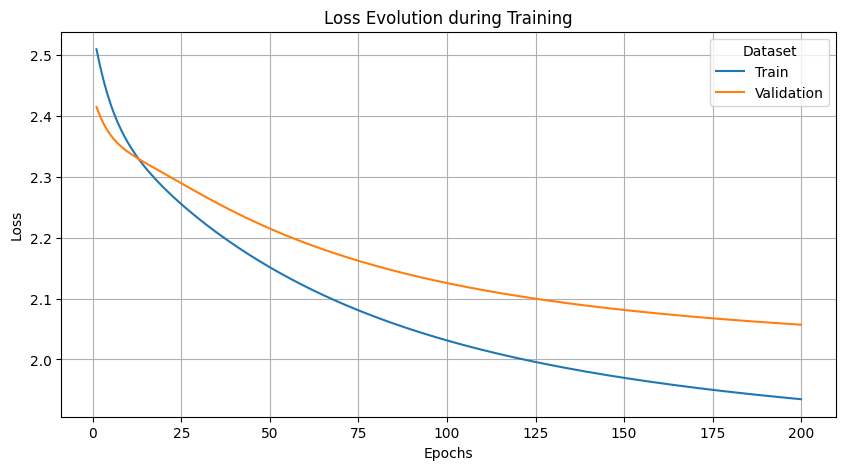

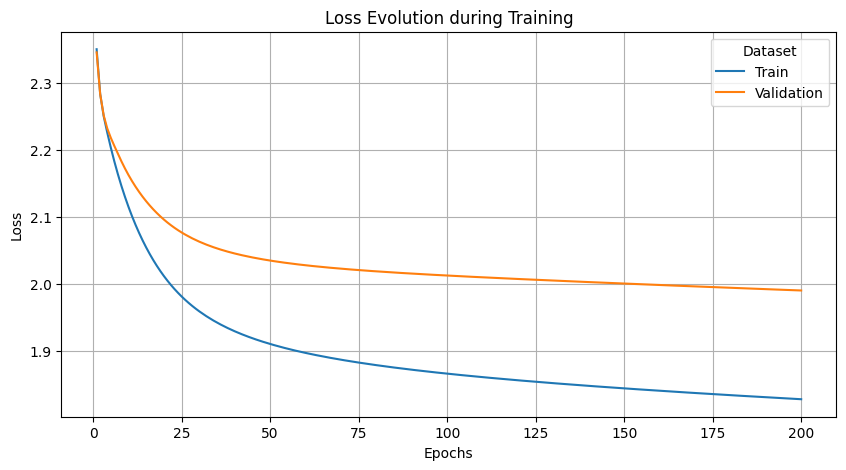

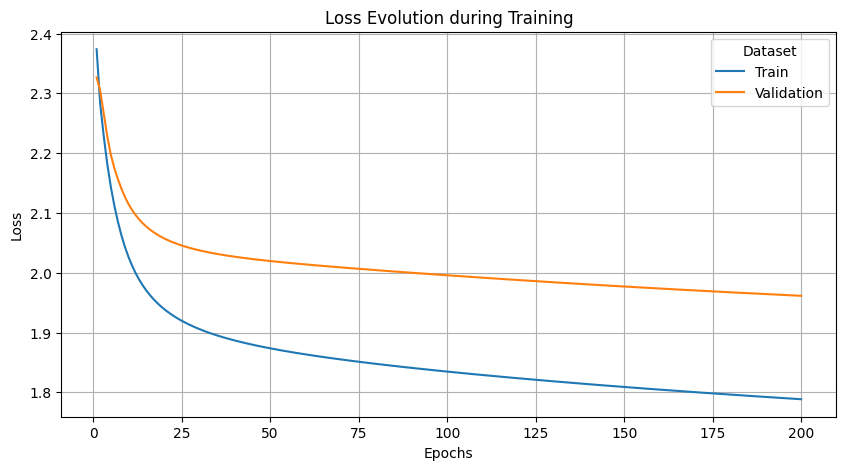

In [51]:
def multiclass_neural_network(learning_rate):
    # Create and compile the model
    # Your code here
    model = Sequential()
    model.add(Input(shape=(len(x_cols),)))
    model.add(Dense(len(y_cols), name='output_layer', activation= 'softmax'))
    #10= len y_cols

    

    optim = Adam(learning_rate=learning_rate)
    model.compile(loss='categorical_crossentropy', optimizer=optim)
    return model


 

# Create the network from scratch
model_mtc1 = multiclass_neural_network(learning_rate = 0.001)
model_mtc2 = multiclass_neural_network(learning_rate = 0.005)
model_mtc3 = multiclass_neural_network(learning_rate = 0.01)


# Train the model
# Your code here

history_mtc1 = model_mtc1.fit(X_train_scaled, Y_train, validation_split=0.2, batch_size=64, epochs=200, verbose=2)
history_mtc2 = model_mtc2.fit(X_train_scaled, Y_train, validation_split=0.2, batch_size=64, epochs=200, verbose=2)
history_mtc3 = model_mtc3.fit(X_train_scaled, Y_train, validation_split=0.2, batch_size=64, epochs=200, verbose=2)


# Visualize the training
# Your code here
plot_loss_history(history_mtc1)
plot_loss_history(history_mtc2)
plot_loss_history(history_mtc3)



#cojo el ultimo pq es más directo y la loss es la más baja

In [73]:
# Train the final model (without validation)
# Your code here

pred= model_mtc3.predict(X_test_scaled)

# Evaluate on test
# Your code here
evaluate_model(Y_test, pred, "Multi CatNN", average='macro')

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


ValueError: Found input variables with inconsistent numbers of samples: [42, 230]

<hr>

## **4. Multilabel Problems**

The last type of problem we need to address is **multilabel classification**, that is, a problem where each example can belong to **one or more classes**.

<div class="alert alert-block alert-success">
    <b>Develop a model that, given the type of tire and the speed in the first sector (<code>"Compound" and "SpeedI1"</code>), can predict the <i>driver(s)</i> (<code>"Driver"</code>) who have used that combination.</b>
</div>
  
As always, the first step is to create the dataset needed to train and evaluate the different models.

### **4.1. Data Preprocessing**

We create the <code>data_drivers</code> variable with the necessary rows and columns to train our models.

In [53]:
from sklearn.preprocessing import MultiLabelBinarizer

data_drivers = data.groupby(['Compound', 'SpeedI1'])['Driver'].apply(lambda x: x.unique()).reset_index()
# Drivers are encoded as multi-hot
mlb = MultiLabelBinarizer()
driver_dummies = pd.DataFrame(mlb.fit_transform(data_drivers['Driver']), columns = map(lambda x: 'Driver_'+str(x), mlb.classes_))
# Add the new columns encoded as numbers
data_drivers = data_drivers = pd.concat([data_drivers.drop(columns = ['Driver']), driver_dummies], axis = 1)

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Separate the X and Y from the <code>data_drivers</code> dataframe, split into training and test (80/20) setting the seed, and finally <b>normalize</b> the X using the <code>MinMaxScaler()</code> class.
    <hr style="margin-bottom:5px">
    You may need to encode some of the columns.
</div>

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Your code here

data_drivers = pd.get_dummies(data_drivers, dtype=int)

x_cols = ['SpeedI1', 'Compound_HARD', 'Compound_INTERMEDIATE', 'Compound_MEDIUM', 'Compound_SOFT', 'Compound_WET']
y_cols = ['Driver_ALB', 'Driver_ALO', 'Driver_BOT', 'Driver_DEV', 'Driver_GAS', 'Driver_HAM', 'Driver_HUL', 'Driver_LEC', 'Driver_MAG', 'Driver_NOR', 'Driver_OCO', 'Driver_PER', 'Driver_PIA', 'Driver_RUS', 'Driver_SAI', 'Driver_SAR', 'Driver_STR', 'Driver_TSU', 'Driver_VER', 'Driver_ZHO']

X = data_drivers[x_cols]
Y = data_drivers[y_cols]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=2533, test_size=.2)

standardizer = MinMaxScaler()
X_train = standardizer.fit_transform(X_train)
X_test = standardizer.transform(X_test)

### **4.2. Machine Learning**

With the data ready, we will train and evaluate the already known machine learning models to compare them with our new system.

<div class="alert alert-block alert-warning">
    <strong>Note:</strong> Remember that the <code>f1_score</code> can be obtained in different ways in problems with multiple classes. In this case, <code>samples</code> seems to be the best option.
</div>

In [55]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

# Baseline Random
baseline_random = DummyClassifier(strategy = 'uniform')
baseline_random.fit(X_train, Y_train)
preds_test = baseline_random.predict(X_test)
evaluate_model(Y_test, preds_test, 'Baseline Random', average = 'samples')

# Baseline Zero-R
baseline_zero = DummyClassifier(strategy = 'most_frequent')
baseline_zero.fit(X_train, Y_train)
preds_test = baseline_zero.predict(X_test)
evaluate_model(Y_test, preds_test, 'Baseline Zero-R', average = 'samples')

# KNN
model_knn = KNeighborsClassifier()
model_knn.fit(X_train, Y_train)
preds_test = model_knn.predict(X_test)
evaluate_model(Y_test, preds_test, 'KNN', average = 'samples')

# Decision Trees
model_tree = DecisionTreeClassifier()
model_tree.fit(X_train, Y_train)
preds_test = model_tree.predict(X_test)
evaluate_model(Y_test, preds_test, 'Tree', average = 'samples')

Results for Baseline Random:
╭──────────┬──────────╮
│ Metric   │     TEST │
├──────────┼──────────┤
│ Accuracy │ 0        │
│ F1       │ 0.190068 │
╰──────────┴──────────╯

Results for Baseline Zero-R:
╭──────────┬────────╮
│ Metric   │   TEST │
├──────────┼────────┤
│ Accuracy │      0 │
│ F1       │      0 │
╰──────────┴────────╯

Results for KNN:
╭──────────┬──────────╮
│ Metric   │     TEST │
├──────────┼──────────┤
│ Accuracy │ 0.142857 │
│ F1       │ 0.451829 │
╰──────────┴──────────╯

Results for Tree:
╭──────────┬──────────╮
│ Metric   │     TEST │
├──────────┼──────────┤
│ Accuracy │ 0.190476 │
│ F1       │ 0.487381 │
╰──────────┴──────────╯



The results should look something like this:

<center>

| Model               | Accuracy (test) | F1 samples (test) |
|---------------------|-----------------|-------------------|
| Baseline Random     | 0.000           | 0.206             | 
| Baseline Zero-R     | 0.000           | 0.000             |
| KNN                 | 0.143           | 0.452             |
| Decision Trees      | 0.190           | 0.487             |

</center>

### **4.3. Deep Learning**

As always, once we have several machine learning models trained to solve our problem, we will try to create a *neural network* to improve the results.

As you remember, in multiclass problems we had multiple outputs (as many as classes) and each example could only belong to one class. In **multilabel classification** problems like this one, we also have as many outputs as classes, but now <u>an example can belong to one or more classes</u>.

For our neural network, this means we can have several ones as output, so we can use a `sigmoid`.

<div class="alert alert-block alert-warning">
    <strong>Note:</strong> Multilabel classification problems can be seen as <i>multiple binary classification problems in parallel</i>.
</div>

Thus, we will use the same loss and activation function in the final layer as in binary classification. Updating our table of *changes* in neural networks based on the problem, we get the following:

<center>

| Type of problem            | Activation function in the final layer      | Loss function               | In *keras*                                    |
|----------------------------|---------------------------------------------|-----------------------------|-----------------------------------------------|
| *Regression*               | None or *ReLU* (if values are positive)    | *MAE* or *MSE*              | `mean_average_error` or `mean_squared_error`   |
| *Binary Classification*    | *Sigmoid*                                  | *Binary Crossentropy*       | `binary_crossentropy`                         |
| *Multiclass Classification*| *Softmax*                                  | *Categorical Crossentropy*  | `categorical_crossentropy`                    |
| *Multilabel Classification*| *Sigmoid*                                  | *Binary Crossentropy*       | `binary_crossentropy`                         |

</center>

<div class="alert alert-block alert-info">
    <b>Exercise:</b> Create a non-linear multilabel neural network to try to improve traditional machine learning models in this task. Find the best <code>learning rate</code>, train, and evaluate the final model on the test set. Fill in both tables.
    <hr style="margin-bottom:5px">
    Set the validation set to 20%, epochs to 200, and batch size to 64. Remember that for training the final model, the validation set is not necessary.
</div>

<center>

| Model                      | Accuracy (train)  | F1 (train) | Accuracy (val)  | F1 (val) |
|----------------------------|-------------------|------------|-----------------|----------|
| *Neural Network (lr=0.001)* |                   |            |                 |          |
| *Neural Network (lr=0.005)* |                   |            |                 |          |
| *Neural Network (lr=0.01)*  |                   |            |                 |          |

</center>
<br>
<center>

| Model               | Accuracy (test) | F1 samples (test) |
|---------------------|-----------------|-------------------|
| Baseline Random     | 0.000           | 0.206             |
| Baseline Zero-R     | 0.000           | 0.000             |
| KNN                 | 0.143           | 0.452             |
| Decision Trees      | 0.190           | 0.487             |
| Neural Network      |                 |                   |

</center>

Epoch 1/200
3/3 - 0s - 97ms/step - loss: 0.6858 - val_loss: 0.6790
Epoch 2/200
3/3 - 0s - 17ms/step - loss: 0.6836 - val_loss: 0.6769
Epoch 3/200
3/3 - 0s - 18ms/step - loss: 0.6814 - val_loss: 0.6749
Epoch 4/200
3/3 - 0s - 18ms/step - loss: 0.6793 - val_loss: 0.6729
Epoch 5/200
3/3 - 0s - 18ms/step - loss: 0.6771 - val_loss: 0.6709
Epoch 6/200
3/3 - 0s - 18ms/step - loss: 0.6750 - val_loss: 0.6689
Epoch 7/200
3/3 - 0s - 18ms/step - loss: 0.6729 - val_loss: 0.6670
Epoch 8/200
3/3 - 0s - 18ms/step - loss: 0.6708 - val_loss: 0.6650
Epoch 9/200
3/3 - 0s - 18ms/step - loss: 0.6688 - val_loss: 0.6631
Epoch 10/200
3/3 - 0s - 18ms/step - loss: 0.6667 - val_loss: 0.6612
Epoch 11/200
3/3 - 0s - 18ms/step - loss: 0.6647 - val_loss: 0.6593
Epoch 12/200
3/3 - 0s - 18ms/step - loss: 0.6626 - val_loss: 0.6574
Epoch 13/200
3/3 - 0s - 20ms/step - loss: 0.6606 - val_loss: 0.6555
Epoch 14/200
3/3 - 0s - 18ms/step - loss: 0.6587 - val_loss: 0.6537
Epoch 15/200
3/3 - 0s - 18ms/step - loss: 0.6567 - val_lo

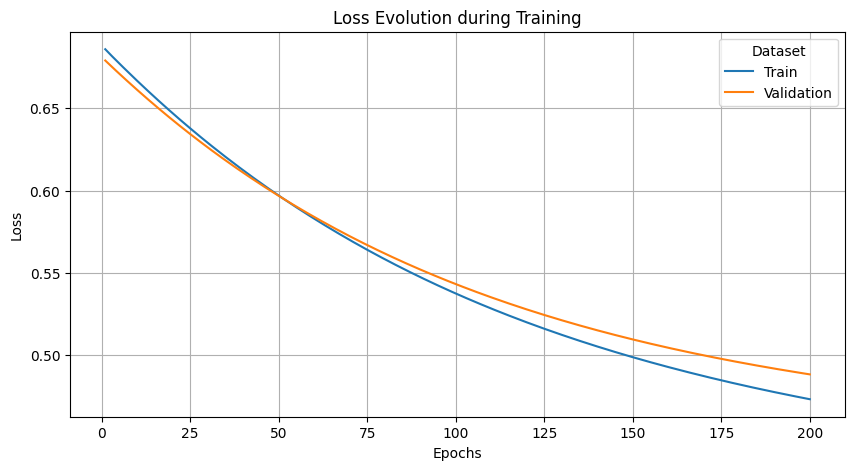

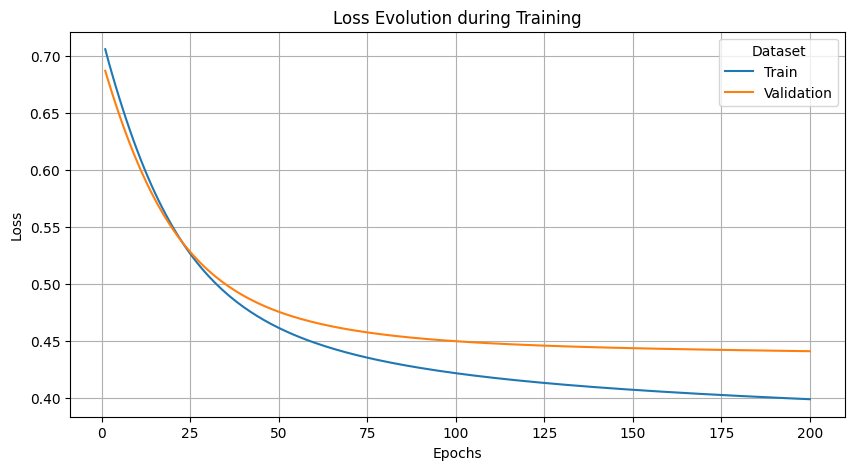

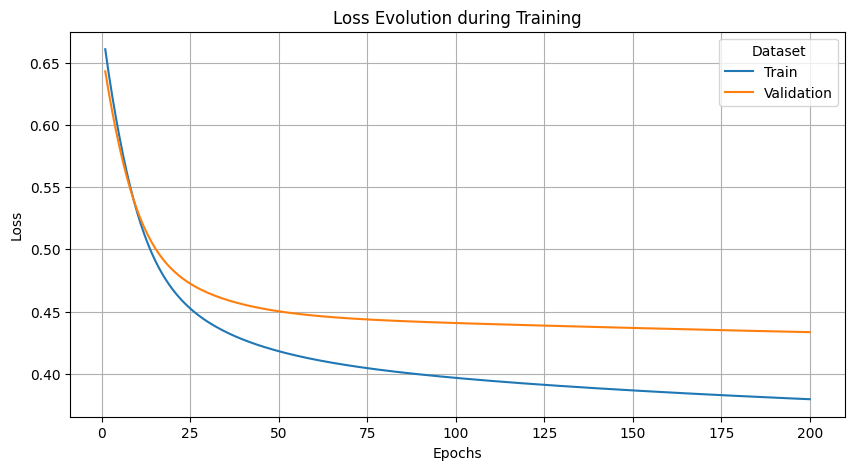

In [66]:
def neural_network_multilabel(learning_rate):
    # We create and compile the model
    model = Sequential()
    model.add(Input(shape=(len(x_cols),)))
    model.add(Dense(len(y_cols), name='output_layer', activation= 'sigmoid'))
    #10= len y_cols
    optim = Adam(learning_rate=learning_rate)
    model.compile(loss='binary_crossentropy', optimizer=optim)
    return model


# We create the network from scratch
model_mtl1 = neural_network_multilabel(learning_rate = 0.001)
model_mtl2 = neural_network_multilabel(learning_rate = 0.005)
model_mtl3 = neural_network_multilabel(learning_rate = 0.01)


# We train the model
# Your code here
history_mtl1 = model_mtl1.fit(X_train, Y_train, validation_split=0.2, batch_size=64, epochs=200, verbose=2)
history_mtl2 = model_mtl2.fit(X_train, Y_train, validation_split=0.2, batch_size=64, epochs=200, verbose=2)
history_mtl3 = model_mtl3.fit(X_train, Y_train, validation_split=0.2, batch_size=64, epochs=200, verbose=2)


# Visualize the training
# Your code here
plot_loss_history(history_mtl1)
plot_loss_history(history_mtl2)
plot_loss_history(history_mtl3)



In [74]:
# Train final model (without validation) 0.01
# Your code here
pred= model_mtl3.predict(X_test)

# Evaluate on test
# Your code here
evaluate_model(Y_test, pred, "Multi lable NN ", average='samples')

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Results for Multi lable NN :
╭──────────┬──────────╮
│ Metric   │     TEST │
├──────────┼──────────┤
│ Accuracy │ 0.142857 │
│ F1       │ 0.249049 │
╰──────────┴──────────╯



<hr>

## **5. Exercises**

<div class="alert alert-block alert-success">
    <b>Create a model that, given the time (in seconds) of the sectors (<code>"Sector1Time", "Sector2Time", and "Sector3Time"</code>) and the speeds (<code>"SpeedI1", "SpeedI2", "SpeedFL", and "SpeedST"</code>), can predict the <i>tyre</i> (<code>"Compound"</code>) used during the lap.</b>
</div>

#multiclase con variables numericas

In [76]:
# Your code here

# Extract the relevant features and target
features = ['Sector1Time', 'Sector2Time', 'Sector3Time', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST']
target = 'Compound'

# Extract the features (X) and the target (Y)
X = data[features]
Y = data[target]


